In [1]:
import numpy as np
import pandas as pd
from scipy.stats import norm
import yfinance as yf

import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter

In [2]:
# Paste the finalized RiskEngine class here

In [3]:
from RiskEngine import RiskEngine

print("RiskEngine imported successfully.")

RiskEngine imported successfully.


In [4]:
risk_factor_prices = pd.DataFrame({
    "EURUSD": [1.10, 1.105, 1.102, 1.108, 1.104],
    "GBPUSD": [1.25, 1.255, 1.252, 1.260, 1.257]
})

sensitivities = pd.Series({
    "EURUSD": 1_000_000,
    "GBPUSD": 500_000
})

print("Risk Factor Prices:")
display(risk_factor_prices)

print("\nSensitivities:")
display(sensitivities)

Risk Factor Prices:


,EURUSD,GBPUSD
0,1.100,1.250
1,1.105,1.255
2,1.102,1.252
3,1.108,1.260
4,1.104,1.257



Sensitivities:


,0
EURUSD,1000000
GBPUSD,500000


In [5]:
engine = RiskEngine(
    sensitivities=sensitivities,
    risk_factor_prices=risk_factor_prices
)

print("RiskEngine object created successfully.")

RiskEngine object created successfully.


In [6]:
historical_var = engine.historical_var(
    confidence=0.95,
    horizon=1
)

print(f"Historical VaR (95%, 1-day): {historical_var:.2f}")

Historical VaR (95%, 1-day): 4667.02


In [7]:
historical_es = engine.historical_es(
    confidence=0.95,
    horizon=1
)

print(f"Historical ES (95%, 1-day): {historical_es:.2f}")

Historical ES (95%, 1-day): 4800.58


In [8]:
parametric_var = engine.parametric_var(
    confidence=0.95,
    horizon=1
)

print(f"Parametric VaR (95%, 1-day): {parametric_var:.2f}")

Parametric VaR (95%, 1-day): 11448.80


In [9]:
parametric_es = engine.parametric_es(
    confidence=0.95,
    horizon=1
)

print(f"Parametric ES (95%, 1-day): {parametric_es:.2f}")

Parametric ES (95%, 1-day): 14357.25


In [10]:
monte_carlo_var = engine.monte_carlo_var(
    confidence=0.95,
    horizon=1,
    simulations=10000,
    seed=42
)

print(f"Monte Carlo VaR (95%, 1-day): {monte_carlo_var:.2f}")

Monte Carlo VaR (95%, 1-day): 10024.72


In [11]:
monte_carlo_es = engine.monte_carlo_es(
    confidence=0.95,
    horizon=1,
    simulations=10000,
    seed=42
)

print(f"Monte Carlo ES (95%, 1-day): {monte_carlo_es:.2f}")

Monte Carlo ES (95%, 1-day): 12796.10


In [12]:
result = engine.calculate(
    confidence=0.95,
    horizon=1,
    methodology="historical"
)

print(result)

{'methodology': 'historical', 'confidence': 0.95, 'horizon': 1, 'VaR': np.float64(4667.02), 'Expected Shortfall': np.float64(4800.58)}


In [13]:
for method in ["historical", "parametric", "monte_carlo"]:
    result = engine.calculate(
        confidence=0.95,
        horizon=1,
        methodology=method
    )

    print(
        f"{method.title():<12} | "
        f"VaR: €{result['VaR']:,.2f} | "
        f"ES: €{result['Expected Shortfall']:,.2f}"
    )

Historical   | VaR: €4,667.02 | ES: €4,800.58
Parametric   | VaR: €11,448.80 | ES: €14,357.25
Monte_Carlo  | VaR: €10,024.72 | ES: €12,796.10


In [14]:
stress_result = engine.stress_loss(stress_return=-0.05)

print(f"Stress Loss: €{stress_result:,.2f}")

Stress Loss: €75,000.00


In [15]:
try:
    engine.calculate(
        confidence=1.5,
        horizon=1,
        methodology="historical"
    )
except ValueError as e:
    print("Validation passed:", e)

Validation passed: Confidence must be between 0 and 1.


In [16]:
try:
    engine.calculate(
        confidence=0.95,
        horizon=0,
        methodology="historical"
    )
except ValueError as e:
    print("Validation passed:", e)

Validation passed: Horizon must be a positive integer.


In [17]:
try:
    engine.calculate(
        confidence=0.95,
        horizon=1,
        methodology="invalid_method"
    )
except ValueError as e:
    print("Validation passed:", e)

Validation passed: Methodology must be one of: historical, parametric, monte_carlo.


In [18]:
for simulations in [0, -1000, 5000.5]:
    try:
        engine.calculate(
            confidence=0.95,
            horizon=1,
            methodology="monte_carlo",
            simulations=simulations
        )
    except ValueError as e:
        print(f"Simulations = {simulations} → Validation passed:", e)

Simulations = 0 → Validation passed: Simulations must be a positive integer.
Simulations = -1000 → Validation passed: Simulations must be a positive integer.
Simulations = 5000.5 → Validation passed: Simulations must be a positive integer.


In [19]:
bad_sensitivities = pd.Series({
    "EURUSD": 1_000_000,
    "USDJPY": 500_000
})

try:
    RiskEngine(
        sensitivities=bad_sensitivities,
        risk_factor_prices=risk_factor_prices
    )
except ValueError as e:
    print("Validation passed:", e)

Validation passed: Risk factors in sensitivities and risk_factor_prices must match.


In [20]:
try:
    engine.calculate(
        confidence=0.95,
        horizon=10,
        methodology="historical"
    )
except ValueError as e:
    print("Validation passed:", e)

Validation passed: Insufficient historical observations for a 10-period horizon.


In [21]:
result_1 = engine.calculate(
    confidence=0.95,
    horizon=1,
    methodology="monte_carlo",
    simulations=10000,
    seed=42
)

result_2 = engine.calculate(
    confidence=0.95,
    horizon=1,
    methodology="monte_carlo",
    simulations=10000,
    seed=42
)

print("Run 1:", result_1)
print("Run 2:", result_2)
print("Reproducibility test:", result_1 == result_2)

Run 1: {'methodology': 'monte_carlo', 'confidence': 0.95, 'horizon': 1, 'VaR': np.float64(10024.72), 'Expected Shortfall': np.float64(12796.1)}
Run 2: {'methodology': 'monte_carlo', 'confidence': 0.95, 'horizon': 1, 'VaR': np.float64(10024.72), 'Expected Shortfall': np.float64(12796.1)}
Reproducibility test: True


## Multi-Asset Portfolio Risk Engine Testing

In [22]:
import pandas as pd
import yfinance as yf

from RiskEngine import RiskEngine

print("Imports successful.")

Imports successful.


In [23]:
sensitivities = pd.Series({
    "EURUSD": 2_500_000,
    "GBPUSD": 2_000_000,
    "USDJPY": 3_000_000,
    "XAUUSD": 2_500_000
})

print("Portfolio sensitivities:")
print(sensitivities)

print("\nTotal portfolio sensitivity: €{:,.0f}".format(
    sensitivities.sum()
))

Portfolio sensitivities:
EURUSD    2500000
GBPUSD    2000000
USDJPY    3000000
XAUUSD    2500000
dtype: int64

Total portfolio sensitivity: €10,000,000


In [24]:
tickers = {
    "EURUSD": "EURUSD=X",
    "GBPUSD": "GBPUSD=X",
    "USDJPY": "JPY=X",
    "XAUUSD": "GC=F"
}

prices = yf.download(
    list(tickers.values()),
    period="5y",
    auto_adjust=False,
    progress=False
)

print("Raw data downloaded successfully.")
print("Shape:", prices.shape)

Raw data downloaded successfully.
Shape: (1301, 24)


In [25]:
risk_factor_prices = pd.DataFrame({
    "EURUSD": prices["Close"]["EURUSD=X"],
    "GBPUSD": prices["Close"]["GBPUSD=X"],
    "USDJPY": prices["Close"]["JPY=X"],
    "XAUUSD": prices["Close"]["GC=F"]
}).dropna()

print("Risk-factor price data:")
print(risk_factor_prices.head())

print("\nShape:", risk_factor_prices.shape)
print("\nRisk factors:", list(risk_factor_prices.columns))

Risk-factor price data:
              EURUSD    GBPUSD      USDJPY       XAUUSD
Date                                                   
2021-11-02  1.159958  1.365542  114.094002  1789.400024
2021-11-03  1.157943  1.361739  113.961998  1763.900024
2021-11-04  1.161575  1.369488  114.070000  1793.500000
2021-11-05  1.155535  1.350860  113.836998  1816.800049
2021-11-08  1.156885  1.349127  113.474998  1828.000000

Shape: (1257, 4)

Risk factors: ['EURUSD', 'GBPUSD', 'USDJPY', 'XAUUSD']


In [26]:
engine = RiskEngine(
    sensitivities=sensitivities,
    risk_factor_prices=risk_factor_prices
)

print("Multi-asset RiskEngine created successfully.")

Multi-asset RiskEngine created successfully.


In [27]:
result = engine.calculate(
    confidence=0.95,
    horizon=1,
    methodology="historical"
)

print(result)

{'methodology': 'historical', 'confidence': 0.95, 'horizon': 1, 'VaR': np.float64(57370.37), 'Expected Shortfall': np.float64(88486.92)}


In [28]:
result = engine.calculate(
    confidence=0.99,
    horizon=1,
    methodology="historical"
)

print(result)

{'methodology': 'historical', 'confidence': 0.99, 'horizon': 1, 'VaR': np.float64(103664.95), 'Expected Shortfall': np.float64(132243.21)}


In [29]:
results = []

methodologies = ["historical", "parametric", "monte_carlo"]
confidence_levels = [0.95, 0.99]
horizons = [1, 10, 21, 252]

for methodology in methodologies:
    for confidence in confidence_levels:
        for horizon in horizons:

            result = engine.calculate(
                confidence=confidence,
                horizon=horizon,
                methodology=methodology
            )

            results.append(result)

results_df = pd.DataFrame(results)

results_df["confidence"] = (
    results_df["confidence"] * 100
).astype(int).astype(str) + "%"

results_df = results_df[
    [
        "methodology",
        "confidence",
        "horizon",
        "VaR",
        "Expected Shortfall"
    ]
]

results_df.columns = [
    "Methodology",
    "Confidence",
    "Horizon (Days)",
    "VaR (€)",
    "Expected Shortfall (€)"
]

print("Multi-Asset Portfolio Risk Test Matrix")
print("=" * 80)

display(
    results_df.style.format({
        "VaR (€)": "€{:,.2f}",
        "Expected Shortfall (€)": "€{:,.2f}"
    })
)

Multi-Asset Portfolio Risk Test Matrix


,Methodology,Confidence,Horizon (Days),VaR (€),Expected Shortfall (€)
0,historical,95%,1,"€57,370.37","€88,486.92"
1,historical,95%,10,"€180,708.82","€232,112.14"
2,historical,95%,21,"€231,825.94","€294,819.52"
3,historical,95%,252,"€105,872.97","€43,044.35"
4,historical,99%,1,"€103,664.95","€132,243.21"
5,historical,99%,10,"€266,088.88","€310,103.46"
6,historical,99%,21,"€345,176.46","€368,423.60"
7,historical,99%,252,"€2,364.43","€28,432.46"
8,parametric,95%,1,"€61,621.62","€77,275.99"
9,parametric,95%,10,"€194,864.67","€244,368.15"


In [30]:
# Diagnostic: inspect the 252-day historical P&L distribution

returns_252 = risk_factor_prices.pct_change(periods=252).dropna()

portfolio_pnl_252 = returns_252 @ sensitivities

for confidence in [0.95, 0.99]:
    threshold = portfolio_pnl_252.quantile(1 - confidence)

    tail_pnl = portfolio_pnl_252[
        portfolio_pnl_252 <= threshold
    ]

    print(f"\nConfidence: {confidence:.0%}")
    print(f"Number of observations: {len(portfolio_pnl_252)}")
    print(f"VaR threshold: €{threshold:,.2f}")
    print(f"VaR loss: €{abs(threshold):,.2f}")
    print(f"Tail observations: {len(tail_pnl)}")
    print(f"Tail mean P&L: €{tail_pnl.mean():,.2f}")
    print(f"ES loss: €{abs(tail_pnl.mean()):,.2f}")


Confidence: 95%
Number of observations: 1005
VaR threshold: €105,872.97
VaR loss: €105,872.97
Tail observations: 51
Tail mean P&L: €43,044.35
ES loss: €43,044.35

Confidence: 99%
Number of observations: 1005
VaR threshold: €2,364.43
VaR loss: €2,364.43
Tail observations: 11
Tail mean P&L: €-28,432.46
ES loss: €28,432.46


In [31]:
print("252-day portfolio P&L statistics")
print("=" * 50)

print(portfolio_pnl_252.describe())

print("\nFive worst 252-day P&L observations:")
print(portfolio_pnl_252.nsmallest(5))

print("\nFive best 252-day P&L observations:")
print(portfolio_pnl_252.nlargest(5))

252-day portfolio P&L statistics
count    1.005000e+03
mean     9.380977e+05
std      5.489624e+05
min     -7.380883e+04
25%      6.825330e+05
50%      8.644433e+05
75%      1.155449e+06
max      2.867806e+06
dtype: float64

Five worst 252-day P&L observations:
Date
2026-10-21   -73808.831508
2026-10-19   -48768.642012
2026-10-26   -48688.970320
2026-10-27   -34294.104692
2022-11-04   -30462.601957
dtype: float64

Five best 252-day P&L observations:
Date
2026-01-28    2.867806e+06
2026-01-29    2.855123e+06
2026-03-02    2.659655e+06
2026-01-26    2.637749e+06
2026-01-27    2.602352e+06
dtype: float64


In [32]:
test_sensitivities = pd.Series({
    "EURUSD":  2_500_000,
    "GBPUSD": -2_000_000,
    "USDJPY":  3_000_000,
    "XAUUSD": -2_500_000
})

test_engine = RiskEngine(
    sensitivities=test_sensitivities,
    risk_factor_prices=risk_factor_prices
)

print("Mixed-direction portfolio created successfully.")
print(test_sensitivities)

Mixed-direction portfolio created successfully.
EURUSD    2500000
GBPUSD   -2000000
USDJPY    3000000
XAUUSD   -2500000
dtype: int64


In [33]:
result = test_engine.calculate(
    confidence=0.95,
    horizon=252,
    methodology="historical"
)

print(result)

{'methodology': 'historical', 'confidence': 0.95, 'horizon': 252, 'VaR': np.float64(1499612.0), 'Expected Shortfall': np.float64(1655403.3)}


In [34]:
results_mixed = []

methodologies = ["historical", "parametric", "monte_carlo"]
confidence_levels = [0.95, 0.99]
horizons = [1, 10, 21, 252]

for methodology in methodologies:
    for confidence in confidence_levels:
        for horizon in horizons:

            result = test_engine.calculate(
                confidence=confidence,
                horizon=horizon,
                methodology=methodology
            )

            results_mixed.append(result)

results_mixed_df = pd.DataFrame(results_mixed)

results_mixed_df["confidence"] = (
    results_mixed_df["confidence"] * 100
).astype(int).astype(str) + "%"

results_mixed_df = results_mixed_df[
    [
        "methodology",
        "confidence",
        "horizon",
        "VaR",
        "Expected Shortfall"
    ]
]

results_mixed_df.columns = [
    "Methodology",
    "Confidence",
    "Horizon (Days)",
    "VaR (€)",
    "Expected Shortfall (€)"
]

print("Mixed-Direction Multi-Asset Portfolio Risk Test Matrix")
print("=" * 85)

display(
    results_mixed_df.style.format({
        "VaR (€)": "€{:,.2f}",
        "Expected Shortfall (€)": "€{:,.2f}"
    })
)

Mixed-Direction Multi-Asset Portfolio Risk Test Matrix


,Methodology,Confidence,Horizon (Days),VaR (€),Expected Shortfall (€)
0,historical,95%,1,"€61,190.89","€81,777.80"
1,historical,95%,10,"€202,556.73","€261,618.32"
2,historical,95%,21,"€315,326.81","€365,248.64"
3,historical,95%,252,"€1,499,612.00","€1,655,403.30"
4,historical,99%,1,"€98,907.02","€115,709.57"
5,historical,99%,10,"€305,612.15","€356,314.14"
6,historical,99%,21,"€392,386.78","€463,309.67"
7,historical,99%,252,"€1,679,718.23","€1,864,683.68"
8,parametric,95%,1,"€59,625.24","€74,772.46"
9,parametric,95%,10,"€188,551.56","€236,451.26"


In [35]:
# Prepare a clean copy of the multi-asset validation results
comparison_df = results_mixed_df.copy()

# Convert confidence back to numeric values for filtering
comparison_df["Confidence_Value"] = (
    comparison_df["Confidence"].str.rstrip("%").astype(float)
)

# -----------------------------
# 95% VaR Comparison
# -----------------------------
var_95 = comparison_df[
    comparison_df["Confidence_Value"] == 95
].pivot(
    index="Horizon (Days)",
    columns="Methodology",
    values="VaR (€)"
).reset_index()

var_95 = var_95[
    ["Horizon (Days)", "historical", "parametric", "monte_carlo"]
]

var_95.columns = [
    "Horizon",
    "Historical VaR",
    "Parametric VaR",
    "Monte Carlo VaR"
]

# -----------------------------
# 99% VaR Comparison
# -----------------------------
var_99 = comparison_df[
    comparison_df["Confidence_Value"] == 99
].pivot(
    index="Horizon (Days)",
    columns="Methodology",
    values="VaR (€)"
).reset_index()

var_99 = var_99[
    ["Horizon (Days)", "historical", "parametric", "monte_carlo"]
]

var_99.columns = [
    "Horizon",
    "Historical VaR",
    "Parametric VaR",
    "Monte Carlo VaR"
]

# -----------------------------
# 95% ES Comparison
# -----------------------------
es_95 = comparison_df[
    comparison_df["Confidence_Value"] == 95
].pivot(
    index="Horizon (Days)",
    columns="Methodology",
    values="Expected Shortfall (€)"
).reset_index()

es_95 = es_95[
    ["Horizon (Days)", "historical", "parametric", "monte_carlo"]
]

es_95.columns = [
    "Horizon",
    "Historical ES",
    "Parametric ES",
    "Monte Carlo ES"
]

# -----------------------------
# 99% ES Comparison
# -----------------------------
es_99 = comparison_df[
    comparison_df["Confidence_Value"] == 99
].pivot(
    index="Horizon (Days)",
    columns="Methodology",
    values="Expected Shortfall (€)"
).reset_index()

es_99 = es_99[
    ["Horizon (Days)", "historical", "parametric", "monte_carlo"]
]

es_99.columns = [
    "Horizon",
    "Historical ES",
    "Parametric ES",
    "Monte Carlo ES"
]

# -----------------------------
# Display tables
# -----------------------------

print("95% Confidence Level — VaR Comparison")
display(
    var_95.style.format({
        "Historical VaR": "€{:,.2f}",
        "Parametric VaR": "€{:,.2f}",
        "Monte Carlo VaR": "€{:,.2f}"
    })
)

print("\n99% Confidence Level — VaR Comparison")
display(
    var_99.style.format({
        "Historical VaR": "€{:,.2f}",
        "Parametric VaR": "€{:,.2f}",
        "Monte Carlo VaR": "€{:,.2f}"
    })
)

print("\n95% Confidence Level — Expected Shortfall Comparison")
display(
    es_95.style.format({
        "Historical ES": "€{:,.2f}",
        "Parametric ES": "€{:,.2f}",
        "Monte Carlo ES": "€{:,.2f}"
    })
)

print("\n99% Confidence Level — Expected Shortfall Comparison")
display(
    es_99.style.format({
        "Historical ES": "€{:,.2f}",
        "Parametric ES": "€{:,.2f}",
        "Monte Carlo ES": "€{:,.2f}"
    })
)

95% Confidence Level — VaR Comparison


,Horizon,Historical VaR,Parametric VaR,Monte Carlo VaR
0,1,"€61,190.89","€59,625.24","€60,101.57"
1,10,"€202,556.73","€188,551.56","€190,057.85"
2,21,"€315,326.81","€273,237.17","€275,419.99"
3,252,"€1,499,612.00","€946,521.33","€954,082.84"



99% Confidence Level — VaR Comparison


,Horizon,Historical VaR,Parametric VaR,Monte Carlo VaR
0,1,"€98,907.02","€84,329.11","€83,824.99"
1,10,"€305,612.15","€266,672.07","€265,077.89"
2,21,"€392,386.78","€386,444.55","€384,134.36"
3,252,"€1,679,718.23","€1,338,683.18","€1,330,680.44"



95% Confidence Level — Expected Shortfall Comparison


,Horizon,Historical ES,Parametric ES,Monte Carlo ES
0,1,"€81,777.80","€74,772.46","€74,533.08"
1,10,"€261,618.32","€236,451.26","€235,694.30"
2,21,"€365,248.64","€342,650.44","€341,553.49"
3,252,"€1,655,403.30","€1,186,975.93","€1,183,176.00"



99% Confidence Level — Expected Shortfall Comparison


,Horizon,Historical ES,Parametric ES,Monte Carlo ES
0,1,"€115,709.57","€96,612.87","€94,278.48"
1,10,"€356,314.14","€305,516.73","€298,134.74"
2,21,"€463,309.67","€442,735.80","€432,038.29"
3,252,"€1,864,683.68","€1,533,681.82","€1,496,624.53"


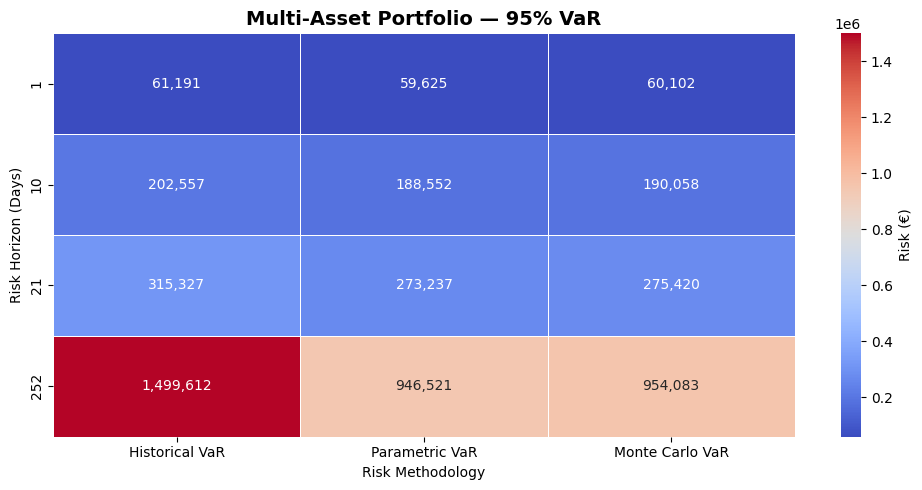

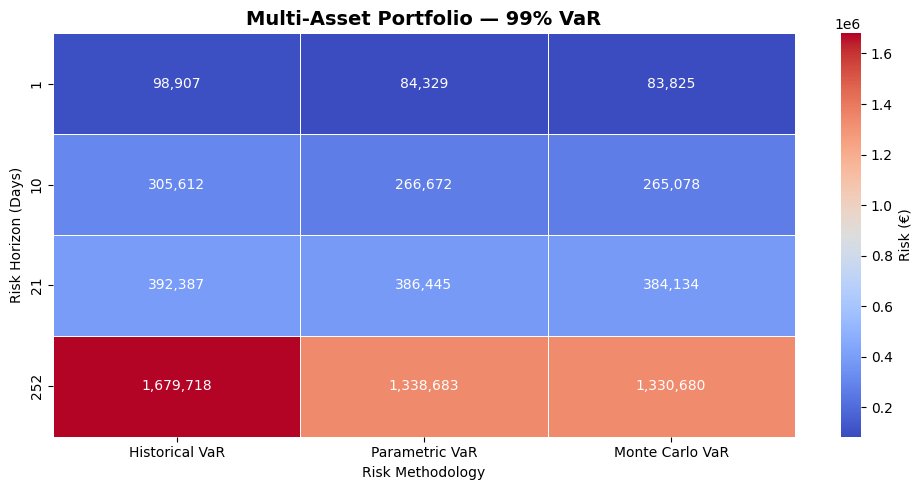

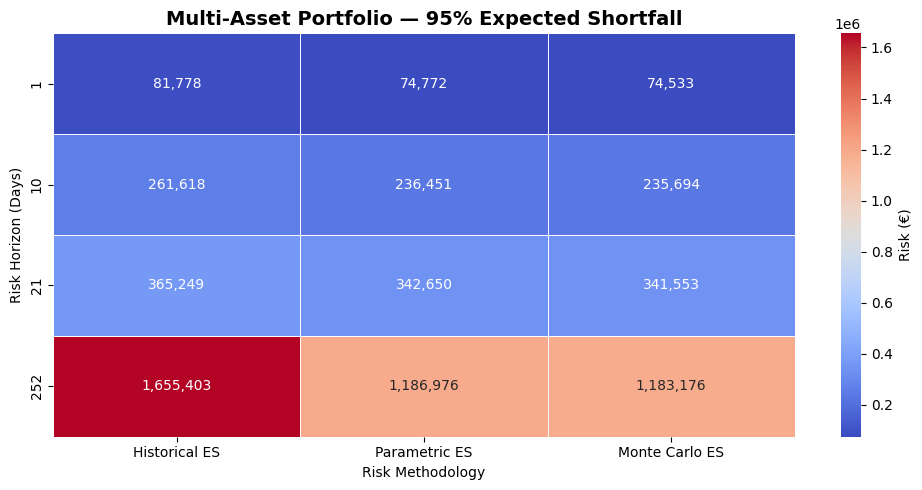

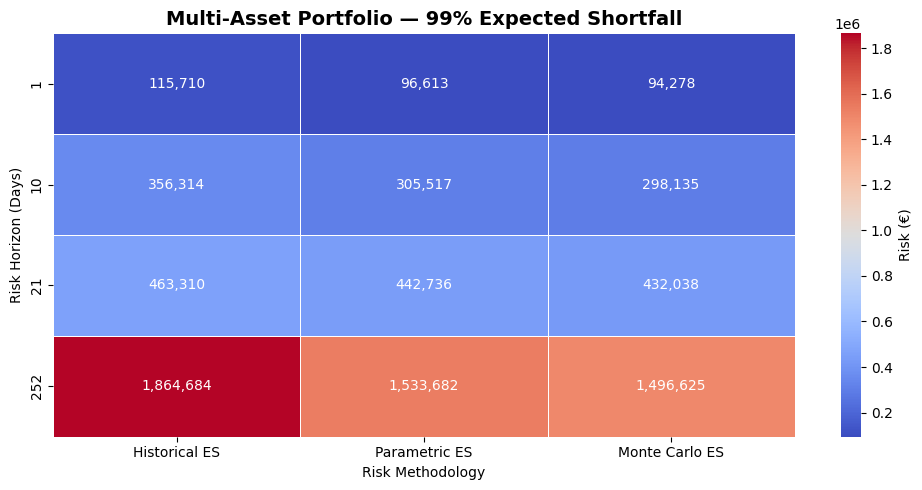

In [36]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create heatmap-ready tables
heatmap_tables = {
    "95% VaR": var_95.set_index("Horizon"),
    "99% VaR": var_99.set_index("Horizon"),
    "95% Expected Shortfall": es_95.set_index("Horizon"),
    "99% Expected Shortfall": es_99.set_index("Horizon")
}

for title, table in heatmap_tables.items():

    plt.figure(figsize=(10, 5))

    sns.heatmap(
        table,
        annot=True,
        fmt=",.0f",
        cmap="coolwarm",
        linewidths=0.5,
        cbar_kws={"label": "Risk (€)"}
    )

    plt.title(
        f"Multi-Asset Portfolio — {title}",
        fontsize=14,
        fontweight="bold"
    )

    plt.xlabel("Risk Methodology")
    plt.ylabel("Risk Horizon (Days)")

    plt.tight_layout()
    plt.show()

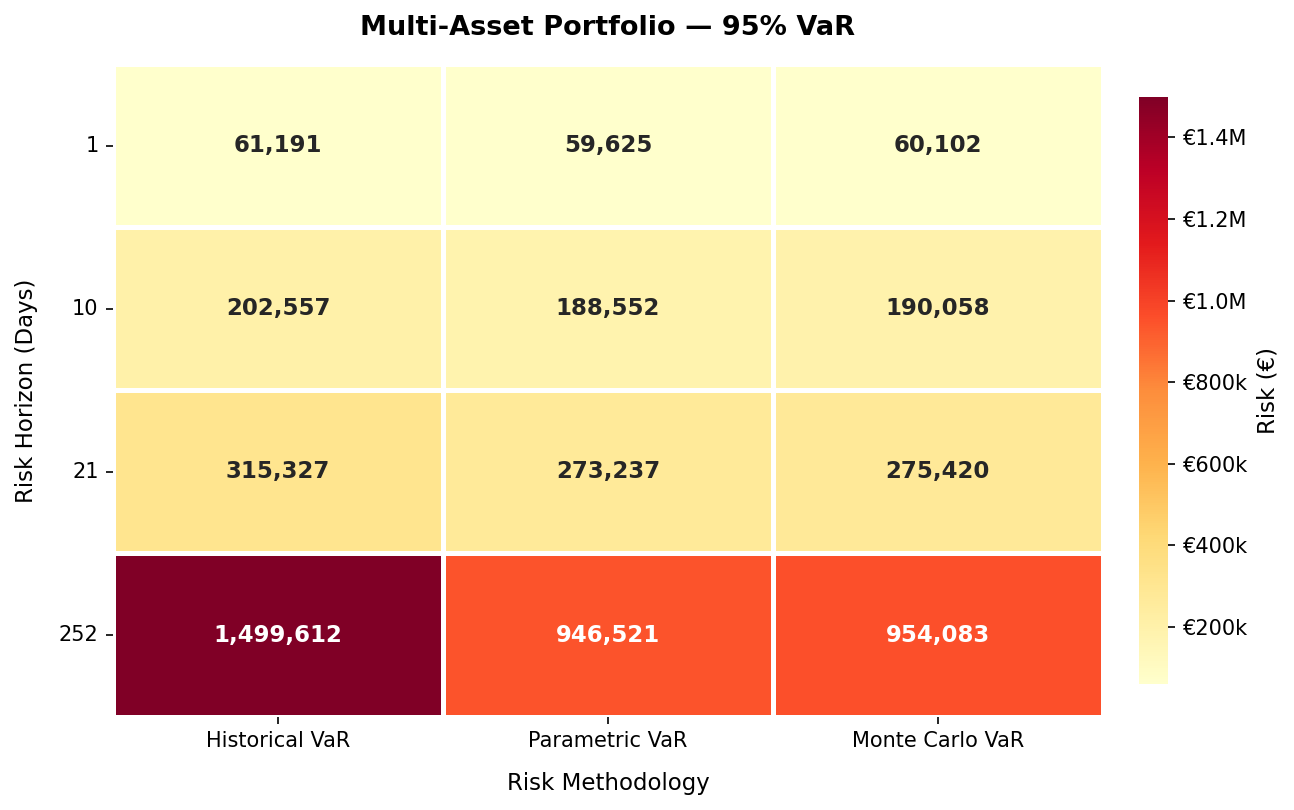

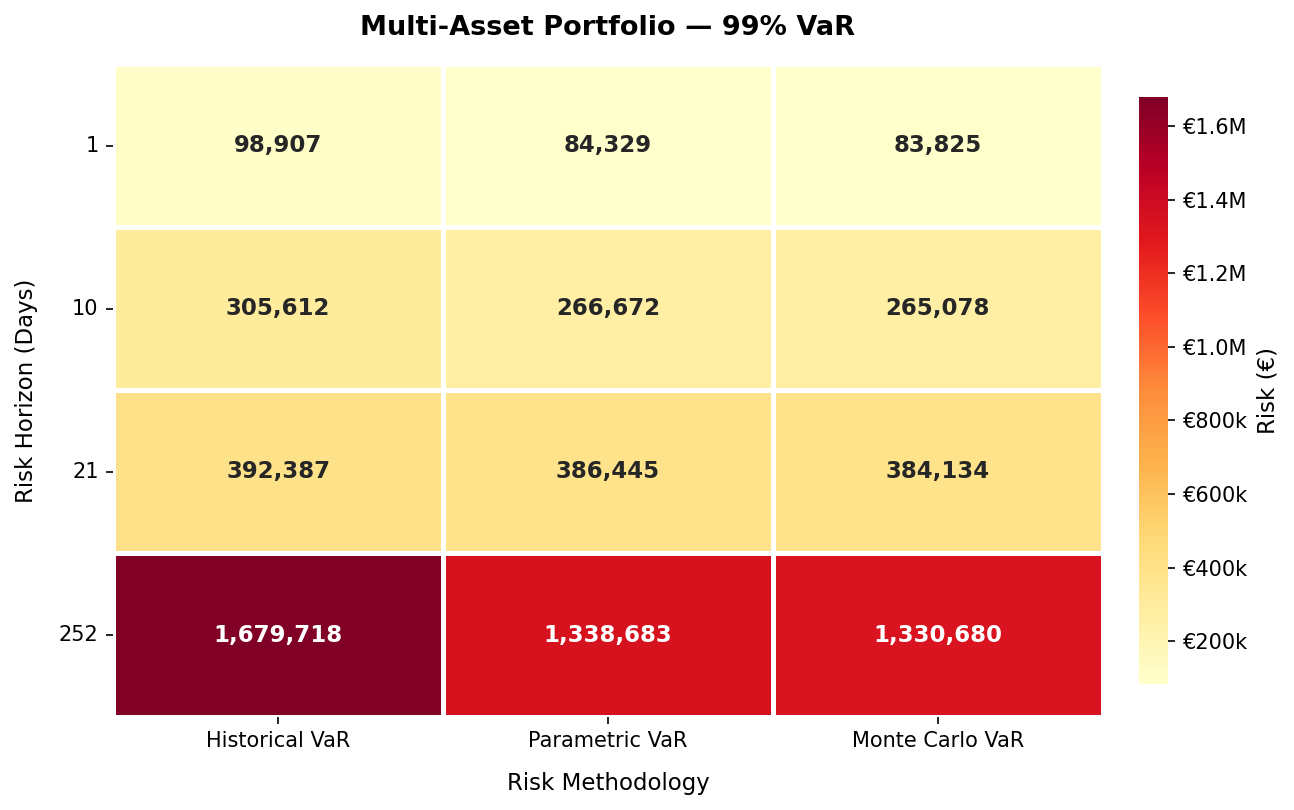

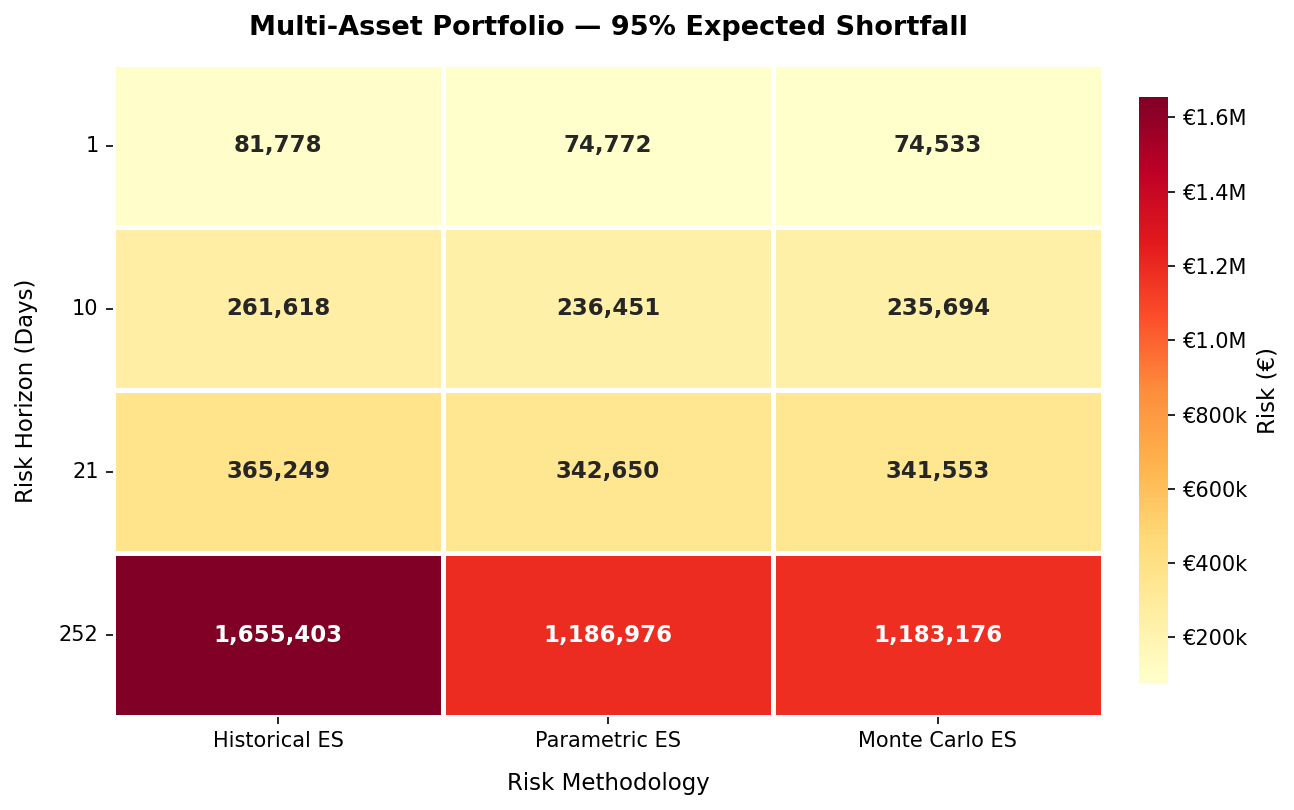

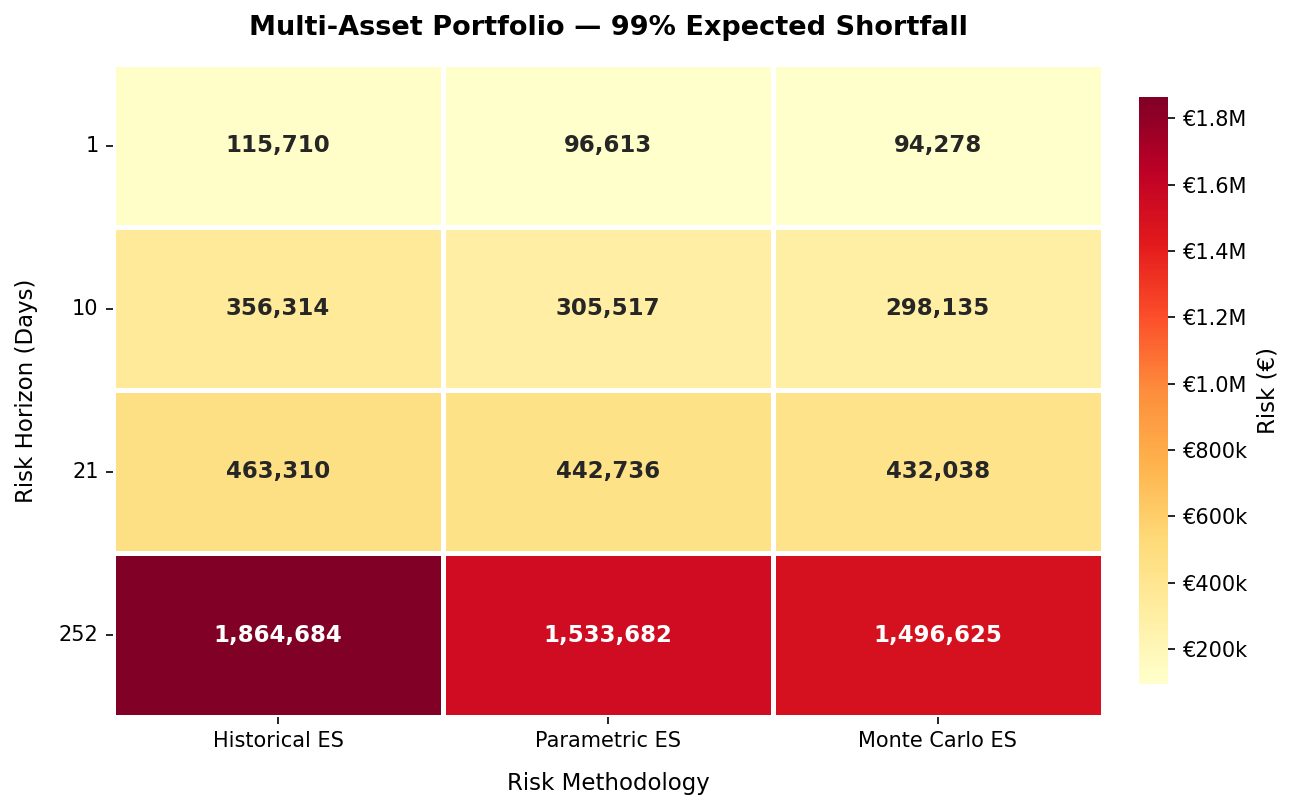

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter

# Create heatmap-ready tables
heatmap_tables = {
    "95% VaR": var_95.set_index("Horizon"),
    "99% VaR": var_99.set_index("Horizon"),
    "95% Expected Shortfall": es_95.set_index("Horizon"),
    "99% Expected Shortfall": es_99.set_index("Horizon")
}

for title, table in heatmap_tables.items():
    fig, ax = plt.subplots(figsize=(9, 5.5), dpi=150)

    # Clean sequential palette for risk escalation
    heatmap = sns.heatmap(
        table,
        annot=True,
        fmt=",.0f",
        cmap="YlOrRd",           # Sequential: light yellow (low risk) -> deep red (high risk)
        linewidths=1.5,
        linecolor="white",       # Clean card-like separation
        annot_kws={"fontsize": 11, "fontweight": "semibold"},
        cbar_kws={
            "label": "Risk (€)",
            "pad": 0.03,
            "shrink": 0.9
        },
        ax=ax
    )

    # Format colorbar to readable currency (€k / €M) without 1e6 offset
    cbar = heatmap.collections[0].colorbar
    cbar.formatter = FuncFormatter(lambda x, pos: f"€{x*1e-6:.1f}M" if x >= 1e6 else f"€{x*1e-3:.0f}k")
    cbar.update_ticks()
    cbar.ax.yaxis.label.set_size(11)

    # Labels and Titles
    ax.set_title(
        f"Multi-Asset Portfolio — {title}",
        fontsize=13,
        fontweight="bold",
        pad=14
    )
    ax.set_xlabel("Risk Methodology", fontsize=11, labelpad=10)
    ax.set_ylabel("Risk Horizon (Days)", fontsize=11, labelpad=10)

    # Keep y-ticks horizontal and easy to read
    ax.tick_params(axis="y", rotation=0)
    ax.tick_params(axis="x", rotation=0)

    plt.tight_layout()
    plt.show()

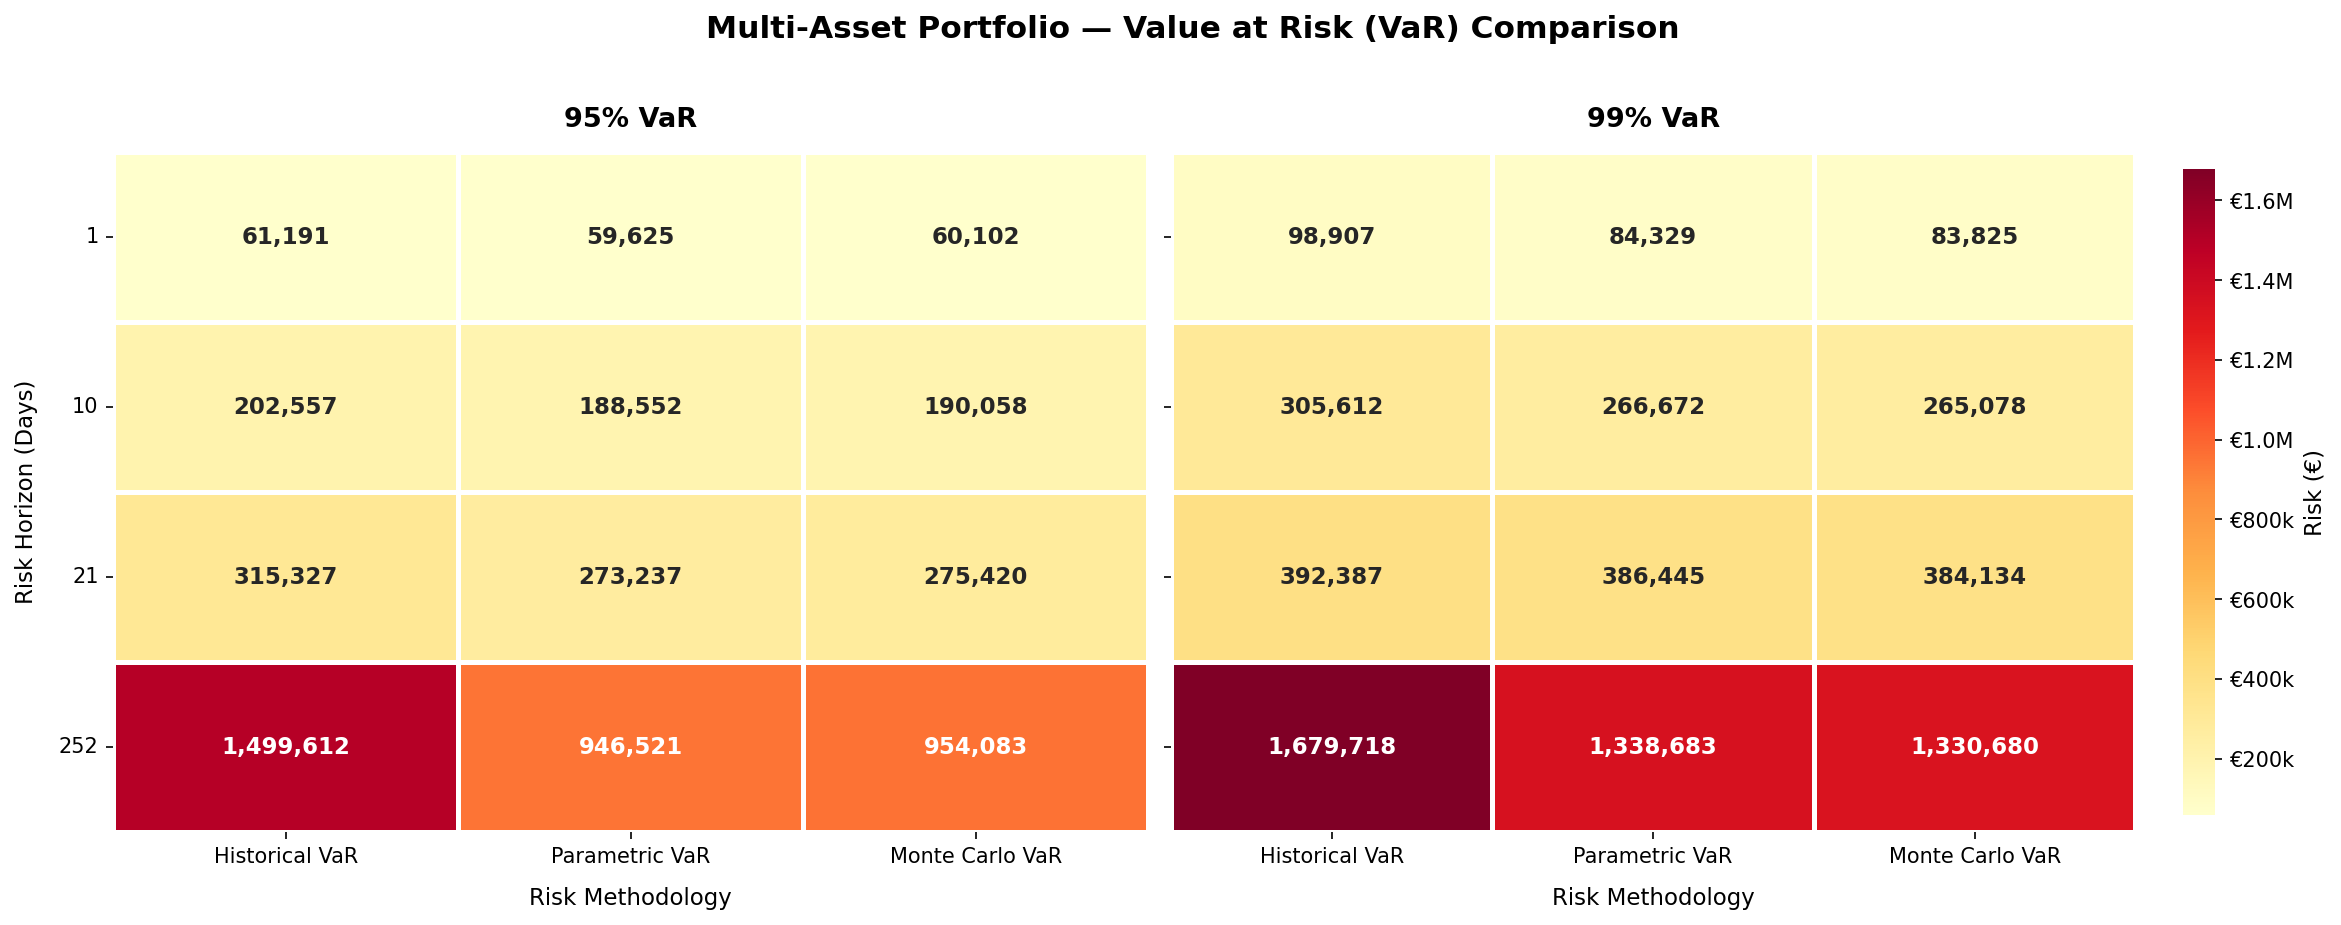

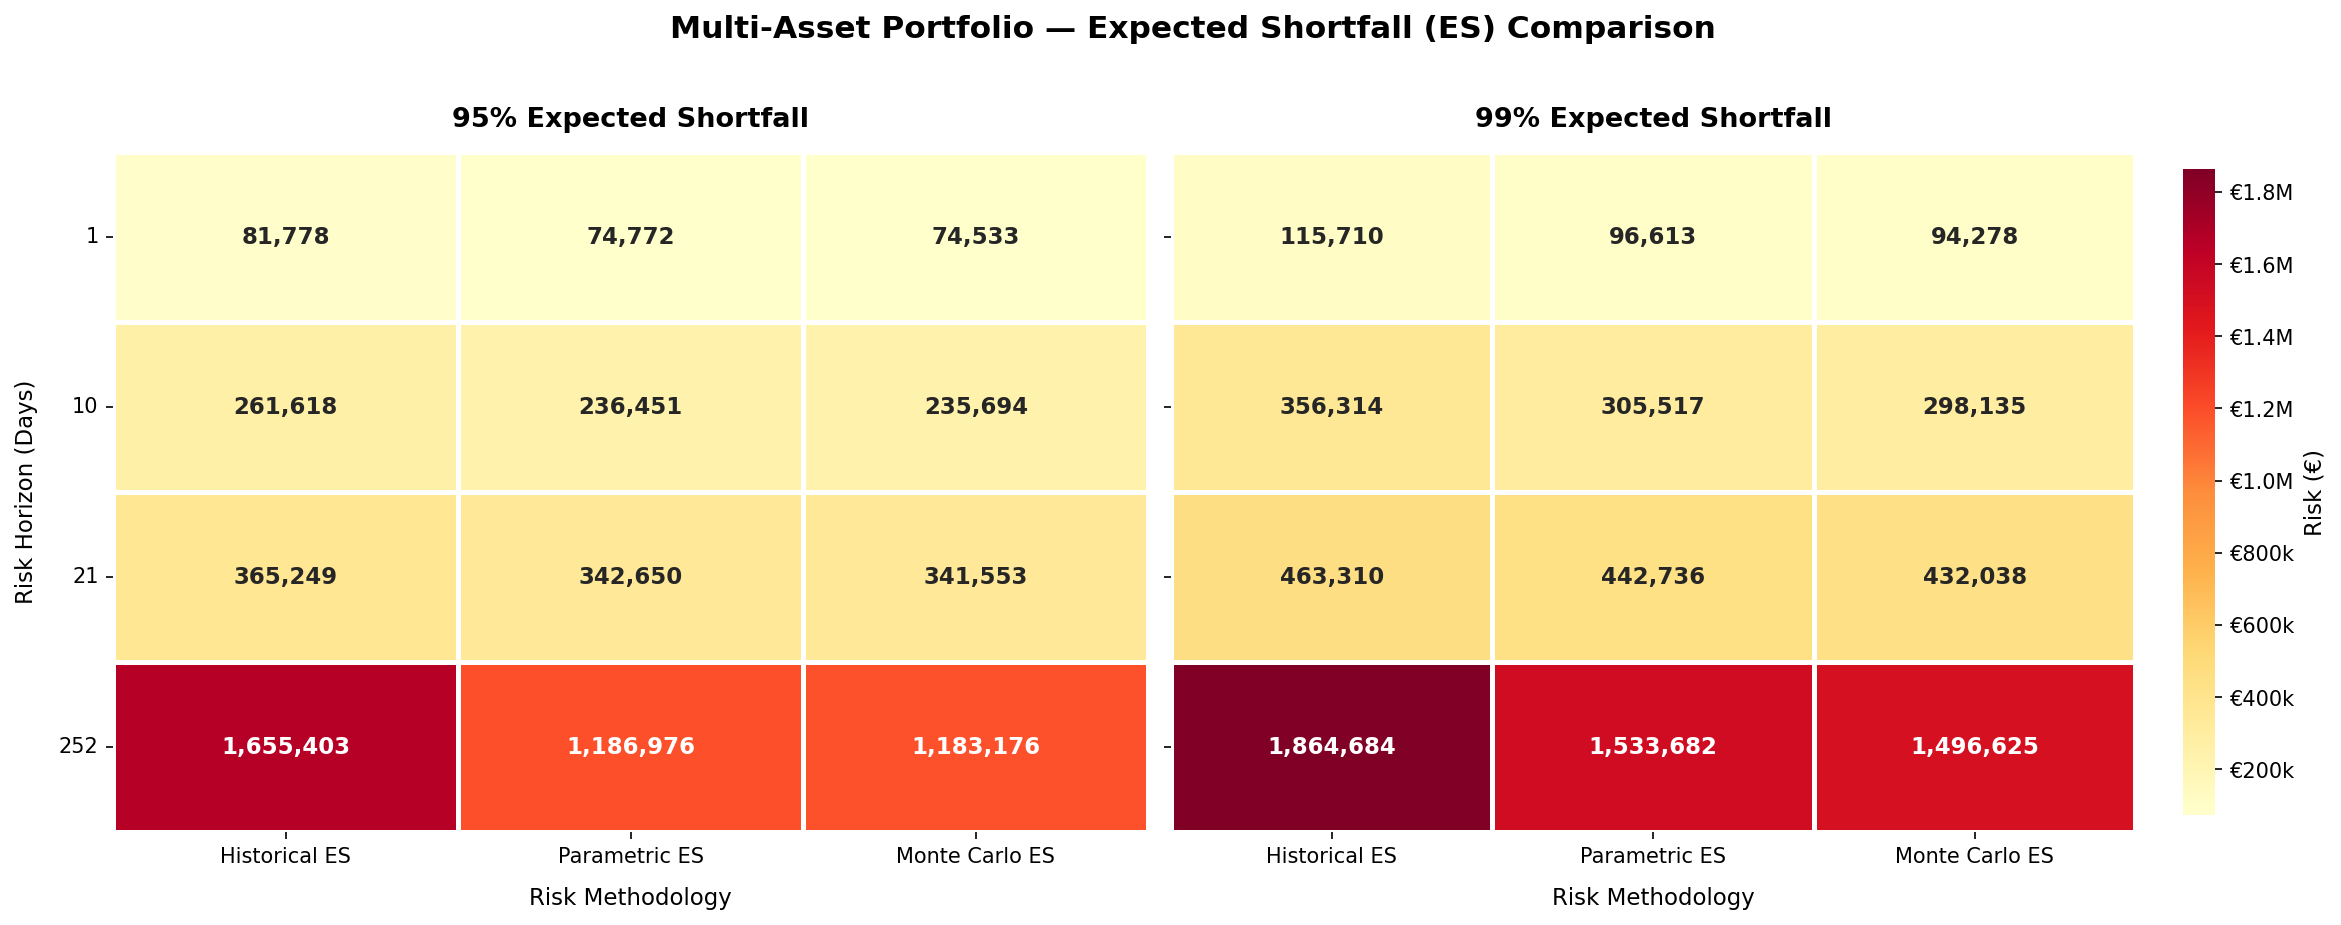

In [38]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter

# 1. Format colorbar helper (€k / €M)
def currency_fmt(x, pos):
    if x >= 1e6:
        return f"€{x*1e-6:.1f}M"
    return f"€{x*1e-3:.0f}k"

formatter = FuncFormatter(currency_fmt)

# 2. Pairs to plot side by side
pairs = [
    {
        "measure": "Value at Risk (VaR)",
        "t1_title": "95% VaR",
        "t1_data": var_95.set_index("Horizon"),
        "t2_title": "99% VaR",
        "t2_data": var_99.set_index("Horizon")
    },
    {
        "measure": "Expected Shortfall (ES)",
        "t1_title": "95% Expected Shortfall",
        "t1_data": es_95.set_index("Horizon"),
        "t2_title": "99% Expected Shortfall",
        "t2_data": es_99.set_index("Horizon")
    }
]

for pair in pairs:
    t1 = pair["t1_data"]
    t2 = pair["t2_data"]

    # Calculate global min and max so color intensities are directly comparable
    vmin = min(t1.values.min(), t2.values.min())
    vmax = max(t1.values.max(), t2.values.max())

    # Create 1 row, 2 columns layout
    fig, axes = plt.subplots(
        1, 2,
        figsize=(16, 6),
        dpi=150,
        sharey=True,
        gridspec_kw={"width_ratios": [1, 1.15]}  # Slightly wider right plot for the colorbar
    )

    # Left plot: 95% Confidence
    sns.heatmap(
        t1,
        annot=True,
        fmt=",.0f",
        cmap="YlOrRd",
        vmin=vmin,
        vmax=vmax,
        linewidths=1.5,
        linecolor="white",
        cbar=False,
        annot_kws={"fontsize": 11, "fontweight": "semibold"},
        ax=axes[0]
    )
    axes[0].set_title(pair["t1_title"], fontsize=13, fontweight="bold", pad=12)
    axes[0].set_xlabel("Risk Methodology", fontsize=11, labelpad=10)
    axes[0].set_ylabel("Risk Horizon (Days)", fontsize=11, labelpad=10)
    axes[0].tick_params(axis="x", rotation=0)
    axes[0].tick_params(axis="y", rotation=0)

    # Right plot: 99% Confidence (with shared colorbar)
    heatmap_right = sns.heatmap(
        t2,
        annot=True,
        fmt=",.0f",
        cmap="YlOrRd",
        vmin=vmin,
        vmax=vmax,
        linewidths=1.5,
        linecolor="white",
        cbar=True,
        cbar_kws={
            "label": "Risk (€)",
            "pad": 0.04,
            "shrink": 0.95
        },
        annot_kws={"fontsize": 11, "fontweight": "semibold"},
        ax=axes[1]
    )
    axes[1].set_title(pair["t2_title"], fontsize=13, fontweight="bold", pad=12)
    axes[1].set_xlabel("Risk Methodology", fontsize=11, labelpad=10)
    axes[1].set_ylabel("")  # Shared Y-axis; hide duplicate label
    axes[1].tick_params(axis="x", rotation=0)
    axes[1].tick_params(axis="y", rotation=0)

    # Format the colorbar ticks to €k / €M
    cbar = heatmap_right.collections[0].colorbar
    cbar.formatter = formatter
    cbar.update_ticks()
    cbar.ax.yaxis.label.set_size(11)

    fig.suptitle(
        f"Multi-Asset Portfolio — {pair['measure']} Comparison",
        fontsize=15,
        fontweight="bold",
        y=1.02
    )

    plt.tight_layout()
    plt.show()

## Edge-Case and Consistency Testing

In [39]:
# =========================================================
# TEST 1 — CONFIDENCE LEVEL CONSISTENCY
# =========================================================

confidence_levels = [0.95, 0.99, 0.999]

confidence_results = []

for confidence in confidence_levels:
    result = test_engine.calculate(
        confidence=confidence,
        horizon=1,
        methodology="historical"
    )

    confidence_results.append({
        "Confidence": confidence,
        "VaR": result["VaR"],
        "Expected Shortfall": result["Expected Shortfall"]
    })

confidence_df = pd.DataFrame(confidence_results)

display(confidence_df)

assert confidence_df["VaR"].is_monotonic_increasing, \
    "VaR should increase as confidence increases."

assert confidence_df["Expected Shortfall"].is_monotonic_increasing, \
    "ES should increase as confidence increases."

print("PASS — Higher confidence produces higher VaR and ES.")

,Confidence,VaR,Expected Shortfall
0,0.950,61190.89,81777.80
1,0.990,98907.02,115709.57
2,0.999,134946.64,146966.51


PASS — Higher confidence produces higher VaR and ES.


In [40]:
# =========================================================
# TEST 2 — EXPECTED SHORTFALL MUST BE >= VaR
# =========================================================

methods = ["historical", "parametric", "monte_carlo"]
confidences = [0.95, 0.99]
horizons = [1, 10, 21, 252]

for method in methods:
    for confidence in confidences:
        for horizon in horizons:

            result = test_engine.calculate(
                confidence=confidence,
                horizon=horizon,
                methodology=method
            )

            assert result["Expected Shortfall"] >= result["VaR"], (
                f"ES < VaR for {method}, "
                f"{confidence:.1%}, {horizon} days."
            )

print("PASS — ES >= VaR across all 24 portfolio scenarios.")

PASS — ES >= VaR across all 24 portfolio scenarios.


In [41]:
# =========================================================
# TEST 3 — MONTE CARLO REPRODUCIBILITY
# =========================================================

mc_result_1 = test_engine.calculate(
    confidence=0.99,
    horizon=10,
    methodology="monte_carlo",
    simulations=10000,
    seed=42
)

mc_result_2 = test_engine.calculate(
    confidence=0.99,
    horizon=10,
    methodology="monte_carlo",
    simulations=10000,
    seed=42
)

assert mc_result_1 == mc_result_2, \
    "Monte Carlo results should be identical with the same seed."

print("PASS — Monte Carlo results are reproducible with the same seed.")

PASS — Monte Carlo results are reproducible with the same seed.


In [42]:
# =========================================================
# TEST 4 — MONTE CARLO SEED SENSITIVITY
# =========================================================

mc_seed_42 = test_engine.calculate(
    confidence=0.99,
    horizon=10,
    methodology="monte_carlo",
    simulations=10000,
    seed=42
)

mc_seed_123 = test_engine.calculate(
    confidence=0.99,
    horizon=10,
    methodology="monte_carlo",
    simulations=10000,
    seed=123
)

print("Seed 42:")
print(mc_seed_42)

print("\nSeed 123:")
print(mc_seed_123)

assert (
    mc_seed_42["VaR"] != mc_seed_123["VaR"]
    or
    mc_seed_42["Expected Shortfall"] != mc_seed_123["Expected Shortfall"]
), "Different seeds should normally produce different Monte Carlo results."

print("\nPASS — Monte Carlo responds to different random seeds.")

Seed 42:
{'methodology': 'monte_carlo', 'confidence': 0.99, 'horizon': 10, 'VaR': np.float64(265077.89), 'Expected Shortfall': np.float64(298134.74)}

Seed 123:
{'methodology': 'monte_carlo', 'confidence': 0.99, 'horizon': 10, 'VaR': np.float64(268073.47), 'Expected Shortfall': np.float64(306109.09)}

PASS — Monte Carlo responds to different random seeds.


In [43]:
# =========================================================
# TEST 5 — HORIZON CONSISTENCY
# =========================================================

horizon_results = []

for horizon in [1, 10, 21, 252]:

    result = test_engine.calculate(
        confidence=0.99,
        horizon=horizon,
        methodology="parametric"
    )

    horizon_results.append({
        "Horizon": horizon,
        "VaR": result["VaR"],
        "Expected Shortfall": result["Expected Shortfall"]
    })

horizon_df = pd.DataFrame(horizon_results)

display(horizon_df)

assert horizon_df["VaR"].is_monotonic_increasing, \
    "Parametric VaR should increase with horizon."

assert horizon_df["Expected Shortfall"].is_monotonic_increasing, \
    "Parametric ES should increase with horizon."

print("PASS — Parametric risk increases across tested horizons.")

,Horizon,VaR,Expected Shortfall
0,1,84329.11,96612.87
1,10,266672.07,305516.73
2,21,386444.55,442735.80
3,252,1338683.18,1533681.82


PASS — Parametric risk increases across tested horizons.


In [44]:
# =========================================================
# TEST 6 — SENSITIVITY SCALING
# =========================================================

base_sensitivities = pd.Series({
    "EURUSD": 2_500_000,
    "GBPUSD": -2_000_000,
    "USDJPY": 3_000_000,
    "XAUUSD": -2_500_000
})

double_sensitivities = base_sensitivities * 2

base_engine = RiskEngine(
    sensitivities=base_sensitivities,
    risk_factor_prices=risk_factor_prices
)

double_engine = RiskEngine(
    sensitivities=double_sensitivities,
    risk_factor_prices=risk_factor_prices
)

# Use the underlying calculation methods directly.
base_var = base_engine.historical_var(
    confidence=0.99,
    horizon=1
)

double_var = double_engine.historical_var(
    confidence=0.99,
    horizon=1
)

base_es = base_engine.historical_es(
    confidence=0.99,
    horizon=1
)

double_es = double_engine.historical_es(
    confidence=0.99,
    horizon=1
)

print(f"Base VaR:              €{base_var:,.10f}")
print(f"Double-sensitivity VaR: €{double_var:,.10f}")

print(f"\nBase ES:               €{base_es:,.10f}")
print(f"Double-sensitivity ES: €{double_es:,.10f}")

# Test linear scaling using full-precision values.
assert np.isclose(
    double_var,
    2 * base_var,
    rtol=1e-10,
    atol=1e-6
), "VaR should scale linearly with portfolio sensitivities."

assert np.isclose(
    double_es,
    2 * base_es,
    rtol=1e-10,
    atol=1e-6
), "ES should scale linearly with portfolio sensitivities."

print("\nPASS — VaR and ES scale linearly with portfolio sensitivities.")

Base VaR:              €98,907.0153992121
Double-sensitivity VaR: €197,814.0307984242

Base ES:               €115,709.5679129731
Double-sensitivity ES: €231,419.1358259463

PASS — VaR and ES scale linearly with portfolio sensitivities.


In [45]:
# =========================================================
# TEST 7 — INVALID CONFIDENCE LEVELS
# =========================================================

invalid_confidences = [
    0,
    -0.01,
    1,
    1.01
]

for confidence in invalid_confidences:

    try:
        test_engine.calculate(
            confidence=confidence,
            horizon=1,
            methodology="historical"
        )

        raise AssertionError(
            f"Invalid confidence {confidence} was accepted."
        )

    except ValueError:
        pass

print("PASS — Invalid confidence levels are rejected.")

PASS — Invalid confidence levels are rejected.


In [46]:
# =========================================================
# TEST 8 — INVALID HORIZONS
# =========================================================

invalid_horizons = [
    0,
    -1,
    1.5,
    "10"
]

for horizon in invalid_horizons:

    try:
        test_engine.calculate(
            confidence=0.95,
            horizon=horizon,
            methodology="historical"
        )

        raise AssertionError(
            f"Invalid horizon {horizon} was accepted."
        )

    except ValueError:
        pass

print("PASS — Invalid horizons are rejected.")

PASS — Invalid horizons are rejected.


In [47]:
# =========================================================
# TEST 9 — INVALID MONTE CARLO SIMULATION COUNTS
# =========================================================

invalid_simulations = [
    0,
    -1000,
    5000.5,
    "10000"
]

for simulations in invalid_simulations:

    try:
        test_engine.calculate(
            confidence=0.95,
            horizon=1,
            methodology="monte_carlo",
            simulations=simulations
        )

        raise AssertionError(
            f"Invalid simulation count {simulations} was accepted."
        )

    except ValueError:
        pass

print("PASS — Invalid simulation counts are rejected.")

PASS — Invalid simulation counts are rejected.


In [48]:
# =========================================================
# TEST 10 — INVALID METHODOLOGY
# =========================================================

invalid_methodologies = [
    "normal",
    "historical_var",
    "black_scholes",
    "",
    "random"
]

for methodology in invalid_methodologies:

    try:
        test_engine.calculate(
            confidence=0.95,
            horizon=1,
            methodology=methodology
        )

        raise AssertionError(
            f"Invalid methodology '{methodology}' was accepted."
        )

    except ValueError:
        pass

print("PASS — Invalid methodologies are rejected.")

PASS — Invalid methodologies are rejected.


In [49]:
# =========================================================
# TEST 11 — MISSING VALUES / NaNs
# =========================================================

prices_with_nan = risk_factor_prices.copy()

# Introduce a missing value
prices_with_nan.iloc[10, 0] = np.nan

try:
    nan_engine = RiskEngine(
        sensitivities=test_sensitivities,
        risk_factor_prices=prices_with_nan
    )

    result = nan_engine.calculate(
        confidence=0.95,
        horizon=1,
        methodology="historical"
    )

    print("RESULT:", result)
    print("WARNING — Engine accepted data containing NaN values.")

except (ValueError, TypeError) as e:
    print("PASS — Missing values are rejected.")
    print("Error:", e)

PASS — Missing values are rejected.
Error: Risk factor prices must contain only finite values.


In [50]:
# =========================================================
# TEST 12 — RISK-FACTOR MISMATCH
# =========================================================

mismatched_sensitivities = pd.Series({
    "EURUSD": 2_500_000,
    "GBPUSD": -2_000_000,
    "USDJPY": 3_000_000,
    "AUDUSD": -2_500_000   # Incorrect factor
})

try:
    mismatch_engine = RiskEngine(
        sensitivities=mismatched_sensitivities,
        risk_factor_prices=risk_factor_prices
    )

    raise AssertionError(
        "Risk-factor mismatch was accepted."
    )

except ValueError as e:
    print("PASS — Risk-factor mismatch is rejected.")
    print("Error:", e)

PASS — Risk-factor mismatch is rejected.
Error: Risk factors in sensitivities and risk_factor_prices must match.


In [51]:
# =========================================================
# TEST 13 — EXTRA SENSITIVITY
# =========================================================

extra_sensitivities = pd.Series({
    "EURUSD":  2_500_000,
    "GBPUSD": -2_000_000,
    "USDJPY":  3_000_000,
    "XAUUSD": -2_500_000,
    "AUDUSD":  1_000_000   # Extra factor
})

try:
    extra_engine = RiskEngine(
        sensitivities=extra_sensitivities,
        risk_factor_prices=risk_factor_prices
    )

    raise AssertionError(
        "Extra sensitivity factor was accepted."
    )

except ValueError as e:
    print("PASS — Extra sensitivity factor is rejected.")
    print("Error:", e)

PASS — Extra sensitivity factor is rejected.
Error: Risk factors in sensitivities and risk_factor_prices must match.


In [52]:
# =========================================================
# TEST 14 — EMPTY PRICE DATAFRAME
# =========================================================

empty_prices = risk_factor_prices.iloc[0:0].copy()

try:
    empty_engine = RiskEngine(
        sensitivities=test_sensitivities,
        risk_factor_prices=empty_prices
    )

    result = empty_engine.calculate(
        confidence=0.95,
        horizon=1,
        methodology="historical"
    )

    print("RESULT:", result)
    print("WARNING — Engine accepted an empty price DataFrame.")

except (ValueError, TypeError) as e:
    print("PASS — Empty price DataFrame is rejected.")
    print("Error:", e)


PASS — Empty price DataFrame is rejected.
Error: Insufficient historical observations for a 1-period horizon.


In [53]:
# =========================================================
# TEST 15 — CONSTANT-PRICE RISK FACTOR
# =========================================================

constant_prices = pd.DataFrame({
    "EURUSD": [1.10] * 20,
    "GBPUSD": [1.25] * 20,
    "USDJPY": [150.00] * 20,
    "XAUUSD": [2500.00] * 20
})

try:
    constant_engine = RiskEngine(
        sensitivities=test_sensitivities,
        risk_factor_prices=constant_prices
    )

    result = constant_engine.calculate(
        confidence=0.95,
        horizon=1,
        methodology="historical"
    )

    print("RESULT:", result)

    if result["VaR"] == 0 and result["Expected Shortfall"] == 0:
        print("PASS — Constant-price factors produce zero historical risk.")
    else:
        print("WARNING — Constant-price factors produced non-zero risk.")

except (ValueError, TypeError, ZeroDivisionError) as e:
    print("PASS — Constant-price input is rejected safely.")
    print("Error:", e)

RESULT: {'methodology': 'historical', 'confidence': 0.95, 'horizon': 1, 'VaR': np.float64(0.0), 'Expected Shortfall': np.float64(0.0)}
PASS — Constant-price factors produce zero historical risk.


In [54]:
# =========================================================
# TEST 16 — INSUFFICIENT OBSERVATIONS
# =========================================================

small_prices = pd.DataFrame({
    "EURUSD": [1.10, 1.105, 1.102, 1.108, 1.104],
    "GBPUSD": [1.25, 1.255, 1.252, 1.260, 1.257]
})

small_sensitivities = pd.Series({
    "EURUSD": 1_000_000,
    "GBPUSD": 500_000
})

small_engine = RiskEngine(
    sensitivities=small_sensitivities,
    risk_factor_prices=small_prices
)

try:
    small_engine.calculate(
        confidence=0.95,
        horizon=252,
        methodology="historical"
    )

    raise AssertionError(
        "Insufficient historical data was accepted."
    )

except ValueError as e:
    print("PASS — Insufficient observations are rejected.")
    print("Error:", e)

PASS — Insufficient observations are rejected.
Error: Insufficient historical observations for a 252-period horizon.


In [55]:
try:
    engine.calculate(
        confidence=0.95,
        horizon=1,
        methodology=123
    )
    print("FAIL — Non-string methodology accepted.")
except (ValueError, TypeError, AttributeError) as e:
    print(f"PASS — Invalid methodology type rejected. Error: {e}")

PASS — Invalid methodology type rejected. Error: Methodology must be a string: historical, parametric, or monte_carlo.


In [56]:
try:
    engine.calculate(
        confidence=0.95,
        horizon=True,
        methodology="historical"
    )
    print("FAIL — Boolean horizon accepted.")
except ValueError as e:
    print(f"PASS — Boolean horizon rejected. Error: {e}")

PASS — Boolean horizon rejected. Error: Horizon must be a positive integer.


In [57]:
try:
    engine.calculate(
        confidence=0.95,
        horizon=1,
        methodology="monte_carlo",
        simulations=True
    )
    print("FAIL — Boolean simulations accepted.")
except ValueError as e:
    print(f"PASS — Boolean simulations rejected. Error: {e}")


PASS — Boolean simulations rejected. Error: Simulations must be a positive integer.


In [58]:
bad_prices = pd.DataFrame({
    "EURUSD": [1.10, 1.105, "bad", 1.108, 1.104],
    "GBPUSD": [1.25, 1.255, 1.252, 1.260, 1.257]
})

try:
    bad_engine = RiskEngine(
        sensitivities=sensitivities,
        risk_factor_prices=bad_prices
    )
    print("FAIL — Non-numeric prices accepted.")
except (ValueError, TypeError) as e:
    print(f"PASS — Non-numeric prices rejected. Error: {e}")

PASS — Non-numeric prices rejected. Error: Risk factor prices must contain numeric values.


In [59]:
inf_prices = risk_factor_prices.copy()
inf_prices.iloc[2, 0] = np.inf

try:
    inf_engine = RiskEngine(
        sensitivities=sensitivities,
        risk_factor_prices=inf_prices
    )
    print("FAIL — Infinite price accepted.")
except ValueError as e:
    print(f"PASS — Infinite price rejected. Error: {e}")

PASS — Infinite price rejected. Error: Risk factor prices must contain only finite values.


In [60]:
duplicate_prices = pd.DataFrame(
    [
        [1.10, 1.105],
        [1.105, 1.255],
        [1.102, 1.252],
        [1.108, 1.260],
        [1.104, 1.257]
    ],
    columns=["EURUSD", "EURUSD"]
)

try:
    duplicate_engine = RiskEngine(
        sensitivities=sensitivities,
        risk_factor_prices=duplicate_prices
    )
    print("FAIL — Duplicate risk-factor names accepted.")
except ValueError as e:
    print(f"PASS — Duplicate risk-factor names rejected. Error: {e}")

PASS — Duplicate risk-factor names rejected. Error: Risk factors in sensitivities and risk_factor_prices must match.


In [61]:
for confidence in [0.0001, 0.01, 0.50, 0.9999]:
    try:
        result = engine.calculate(
            confidence=confidence,
            horizon=1,
            methodology="historical"
        )
        print(f"PASS — Confidence {confidence} accepted.")
    except Exception as e:
        print(f"FAIL — Confidence {confidence} rejected: {e}")

PASS — Confidence 0.0001 accepted.
PASS — Confidence 0.01 accepted.
PASS — Confidence 0.5 accepted.
PASS — Confidence 0.9999 accepted.


In [62]:
result = engine.calculate(
    confidence=0.95,
    horizon=1,
    methodology="historical"
)

print(result)

{'methodology': 'historical', 'confidence': 0.95, 'horizon': 1, 'VaR': np.float64(57370.37), 'Expected Shortfall': np.float64(88486.92)}


In [63]:
try:
    result = engine.calculate(
        confidence=0.95,
        horizon=len(risk_factor_prices) - 1,
        methodology="historical"
    )
    print("PASS — Maximum feasible horizon handled.")
    print(result)
except Exception as e:
    print(f"FAIL — Maximum feasible horizon failed: {e}")

PASS — Maximum feasible horizon handled.
{'methodology': 'historical', 'confidence': 0.95, 'horizon': 1256, 'VaR': np.float64(3989407.99), 'Expected Shortfall': np.float64(3989407.99)}


In [64]:
bad_prices = risk_factor_prices.copy()

bad_prices.iloc[2, 0] = "bad"

try:
    bad_engine = RiskEngine(
        sensitivities=sensitivities,
        risk_factor_prices=bad_prices
    )
    print("FAIL — Non-numeric prices accepted.")
except (ValueError, TypeError) as e:
    print(f"PASS — Non-numeric prices rejected. Error: {e}")

PASS — Non-numeric prices rejected. Error: Risk factor prices must contain numeric values.


/tmp/ipykernel_4618/1689143636.py:3: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'bad' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  bad_prices.iloc[2, 0] = "bad"


In [65]:
inf_prices = risk_factor_prices.copy()

inf_prices.iloc[2, 0] = np.inf

try:
    inf_engine = RiskEngine(
        sensitivities=sensitivities,
        risk_factor_prices=inf_prices
    )
    print("FAIL — Infinite price accepted.")
except (ValueError, TypeError) as e:
    print(f"PASS — Infinite prices rejected. Error: {e}")

PASS — Infinite prices rejected. Error: Risk factor prices must contain only finite values.


In [66]:
risk_factor_prices = pd.DataFrame({
    "EURUSD": [1.10, 1.105, 1.102, 1.108, 1.104],
    "GBPUSD": [1.25, 1.255, 1.252, 1.260, 1.257]
})

sensitivities = pd.Series({
    "EURUSD": 1_000_000,
    "GBPUSD": 500_000
})

engine = RiskEngine(
    sensitivities=sensitivities,
    risk_factor_prices=risk_factor_prices
)

In [67]:
result = engine.calculate(
    confidence=0.95,
    horizon=1,
    methodology="historical"
)

print(result)

assert result["VaR"] >= 0
assert result["Expected Shortfall"] >= result["VaR"]

print("PASS — Historical VaR/ES regression.")

{'methodology': 'historical', 'confidence': 0.95, 'horizon': 1, 'VaR': np.float64(4667.02), 'Expected Shortfall': np.float64(4800.58)}
PASS — Historical VaR/ES regression.


In [68]:
result = engine.calculate(
    confidence=0.95,
    horizon=1,
    methodology="parametric"
)

print(result)

assert result["VaR"] >= 0
assert result["Expected Shortfall"] >= result["VaR"]

print("PASS — Parametric VaR/ES regression.")

{'methodology': 'parametric', 'confidence': 0.95, 'horizon': 1, 'VaR': np.float64(11448.8), 'Expected Shortfall': np.float64(14357.25)}
PASS — Parametric VaR/ES regression.


In [69]:
result = engine.calculate(
    confidence=0.95,
    horizon=1,
    methodology="monte_carlo",
    simulations=10000,
    seed=42
)

print(result)

assert result["VaR"] >= 0
assert result["Expected Shortfall"] >= result["VaR"]

print("PASS — Monte Carlo VaR/ES regression.")

{'methodology': 'monte_carlo', 'confidence': 0.95, 'horizon': 1, 'VaR': np.float64(10024.72), 'Expected Shortfall': np.float64(12796.1)}
PASS — Monte Carlo VaR/ES regression.


In [70]:
stress = engine.stress_loss(-0.05)

print("Stress loss:", stress)

assert stress >= 0

print("PASS — Stress loss regression.")

Stress loss: 75000.0
PASS — Stress loss regression.


In [71]:
result_1 = engine.calculate(
    confidence=0.95,
    horizon=10,
    methodology="monte_carlo",
    simulations=10000,
    seed=42
)

result_2 = engine.calculate(
    confidence=0.95,
    horizon=10,
    methodology="monte_carlo",
    simulations=10000,
    seed=42
)

assert result_1 == result_2

print("PASS — Monte Carlo reproducibility.")
print(result_1)

PASS — Monte Carlo reproducibility.
{'methodology': 'monte_carlo', 'confidence': 0.95, 'horizon': 10, 'VaR': np.float64(31700.94), 'Expected Shortfall': np.float64(40464.82)}


In [72]:
methodologies = [
    "historical",
    "parametric",
    "monte_carlo"
]

horizons = [1, 10, 21, 252]

for methodology in methodologies:

    for horizon in horizons:

        result = eurusd_engine.calculate(
            confidence=0.95,
            horizon=horizon,
            methodology=methodology,
            simulations=10000,
            seed=42
        )

        assert result["VaR"] >= 0
        assert result["Expected Shortfall"] >= result["VaR"]

        print(
            methodology,
            horizon,
            result["VaR"],
            result["Expected Shortfall"]
        )

print("PASS — Real-data methodology/horizon regression matrix.")

NameError: name 'eurusd_engine' is not defined

In [73]:
eurusd_data = yf.download(
    "EURUSD=X",
    period="5y",
    auto_adjust=False,
    progress=False
)

eurusd_prices = (
    eurusd_data["Close"]
    .squeeze()
    .dropna()
)

eurusd_prices = pd.DataFrame({
    "EURUSD": eurusd_prices
})

eurusd_sensitivities = pd.Series({
    "EURUSD": 10_000_000
})

eurusd_engine = RiskEngine(
    sensitivities=eurusd_sensitivities,
    risk_factor_prices=eurusd_prices
)

In [74]:
result = eurusd_engine.calculate(
    confidence=0.99,
    horizon=1,
    methodology="historical"
)

print(result)

{'methodology': 'historical', 'confidence': 0.99, 'horizon': 1, 'VaR': np.float64(123116.11), 'Expected Shortfall': np.float64(147247.42)}


In [75]:
result = engine.calculate(
    confidence=0.95,
    horizon=1,
    methodology="historical"
)

print(result)

{'methodology': 'historical', 'confidence': 0.95, 'horizon': 1, 'VaR': np.float64(4667.02), 'Expected Shortfall': np.float64(4800.58)}


In [76]:
import numpy as np
import pandas as pd

from RiskEngine import RiskEngine


# ============================================================
# 17C — FINAL REGRESSION TEST SUITE
# ============================================================

print("=" * 70)
print("17C — FINAL REGRESSION TEST SUITE")
print("=" * 70)


# ------------------------------------------------------------
# 1. Small practice dataset
# ------------------------------------------------------------

prices = pd.DataFrame({
    "EURUSD": [1.10, 1.11, 1.09, 1.12, 1.08, 1.13],
    "GBPUSD": [1.25, 1.26, 1.24, 1.27, 1.23, 1.28]
})

sensitivities = pd.Series({
    "EURUSD": 1_000_000,
    "GBPUSD": 500_000
})

engine = RiskEngine(
    sensitivities=sensitivities,
    risk_factor_prices=prices
)


# ------------------------------------------------------------
# 2. Core Historical VaR / ES
# ------------------------------------------------------------

result_hist = engine.calculate(
    confidence=0.95,
    horizon=1,
    methodology="historical"
)

print("\n[1] Historical 95% 1-day")
print(result_hist)

assert abs(result_hist["VaR"] - 46360.76) < 0.01
assert abs(
    result_hist["Expected Shortfall"] - 51462.32
) < 0.01

print("PASS")


# ------------------------------------------------------------
# 3. Core Parametric VaR / ES
# ------------------------------------------------------------

result_param = engine.calculate(
    confidence=0.95,
    horizon=1,
    methodology="parametric"
)

print("\n[2] Parametric 95% 1-day")
print(result_param)

assert abs(result_param["VaR"] - 78670.39) < 0.01
assert abs(
    result_param["Expected Shortfall"] - 98655.84
) < 0.01

print("PASS")


# ------------------------------------------------------------
# 4. Core Monte Carlo VaR / ES
# ------------------------------------------------------------

result_mc = engine.calculate(
    confidence=0.95,
    horizon=1,
    methodology="monte_carlo",
    simulations=10000,
    seed=42
)

print("\n[3] Monte Carlo 95% 1-day")
print(result_mc)

assert abs(result_mc["VaR"] - 71719.03) < 0.01
assert abs(
    result_mc["Expected Shortfall"] - 90656.35
) < 0.01

print("PASS")


# ------------------------------------------------------------
# 5. Stress test
# ------------------------------------------------------------

stress = engine.stress_loss(-0.05)

print("\n[4] Stress test: -5%")
print("Stress Loss:", stress)

assert abs(stress - 75000) < 0.01

print("PASS")


# ------------------------------------------------------------
# 6. Monte Carlo reproducibility
# ------------------------------------------------------------

mc_1 = engine.calculate(
    confidence=0.95,
    horizon=10,
    methodology="monte_carlo",
    simulations=10000,
    seed=42
)

mc_2 = engine.calculate(
    confidence=0.95,
    horizon=10,
    methodology="monte_carlo",
    simulations=10000,
    seed=42
)

print("\n[5] Monte Carlo reproducibility")
print("Run 1:", mc_1)
print("Run 2:", mc_2)

assert mc_1 == mc_2

print("PASS")


# ============================================================
# REAL EUR/USD REGRESSION
# ============================================================

print("\n" + "=" * 70)
print("REAL EUR/USD REGRESSION")
print("=" * 70)


# ------------------------------------------------------------
# 7. Real EUR/USD dataset
# ------------------------------------------------------------

import yfinance as yf

eurusd = yf.download(
    "EURUSD=X",
    period="5y",
    auto_adjust=False,
    progress=False
)

if isinstance(eurusd.columns, pd.MultiIndex):
    close = eurusd["Close"].iloc[:, 0]
else:
    close = eurusd["Close"]

close = close.dropna()

risk_factor_prices = pd.DataFrame({
    "EURUSD": close
})

risk_factor_sensitivities = pd.Series({
    "EURUSD": 10_000_000
})

real_engine = RiskEngine(
    sensitivities=risk_factor_sensitivities,
    risk_factor_prices=risk_factor_prices
)


# ------------------------------------------------------------
# 8. Historical 99% 1-day
# ------------------------------------------------------------

real_hist = real_engine.calculate(
    confidence=0.99,
    horizon=1,
    methodology="historical"
)

print("\n[6] Real EUR/USD Historical 99% 1-day")
print(real_hist)

# Live-data baseline
# Small differences can occur as Yahoo Finance data is updated.
assert abs(real_hist["VaR"] - 123116.11) < 1.00

assert abs(
    real_hist["Expected Shortfall"] - 147247.42
) < 1.00

print("PASS")


# ============================================================
# 12-CASE REAL-DATA REGRESSION MATRIX
# ============================================================

print("\n" + "=" * 70)
print("12-CASE REAL-DATA REGRESSION MATRIX")
print("=" * 70)


# ------------------------------------------------------------
# 9. Live-data regression matrix
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("12-CASE REAL-DATA REGRESSION MATRIX")
print("=" * 70)

for methodology in [
    "historical",
    "parametric",
    "monte_carlo"
]:

    for horizon in [1, 10, 21, 252]:

        result = real_engine.calculate(
            confidence=0.95,
            horizon=horizon,
            methodology=methodology,
            simulations=10000,
            seed=42
        )

        var_value = result["VaR"]
        es_value = result["Expected Shortfall"]

        print(
            f"{methodology:12s} | "
            f"{horizon:3d}d | "
            f"VaR={var_value:,.2f} | "
            f"ES={es_value:,.2f}"
        )

        # ----------------------------------------------------
        # Live-data sanity checks
        # ----------------------------------------------------

        assert np.isfinite(var_value)
        assert np.isfinite(es_value)

        assert var_value > 0
        assert es_value > 0

        # Expected Shortfall should be at least as large
        # as VaR for a loss-based risk measure.
        assert es_value >= var_value

        print("PASS")


# ============================================================
# 11. Final summary
# ============================================================

print("\n" + "=" * 70)
print("17C FINAL REGRESSION: ALL TESTS PASSED")
print("=" * 70)

17C — FINAL REGRESSION TEST SUITE

[1] Historical 95% 1-day
{'methodology': 'historical', 'confidence': 0.95, 'horizon': 1, 'VaR': np.float64(46360.76), 'Expected Shortfall': np.float64(51462.32)}
PASS

[2] Parametric 95% 1-day
{'methodology': 'parametric', 'confidence': 0.95, 'horizon': 1, 'VaR': np.float64(78670.39), 'Expected Shortfall': np.float64(98655.84)}
PASS

[3] Monte Carlo 95% 1-day
{'methodology': 'monte_carlo', 'confidence': 0.95, 'horizon': 1, 'VaR': np.float64(71719.03), 'Expected Shortfall': np.float64(90656.35)}
PASS

[4] Stress test: -5%
Stress Loss: 75000.0
PASS

[5] Monte Carlo reproducibility
Run 1: {'methodology': 'monte_carlo', 'confidence': 0.95, 'horizon': 10, 'VaR': np.float64(226795.48), 'Expected Shortfall': np.float64(286680.56)}
Run 2: {'methodology': 'monte_carlo', 'confidence': 0.95, 'horizon': 10, 'VaR': np.float64(226795.48), 'Expected Shortfall': np.float64(286680.56)}
PASS

REAL EUR/USD REGRESSION

[6] Real EUR/USD Historical 99% 1-day
{'methodology'

In [77]:
print("Current practice-data result:")
print(result_hist)

print("\nCurrent engine:")
print(engine)

Current practice-data result:
{'methodology': 'historical', 'confidence': 0.95, 'horizon': 1, 'VaR': np.float64(46360.76), 'Expected Shortfall': np.float64(51462.32)}

Current engine:


In [78]:
# Recalculate practice-data Historical VaR/ES
practice_hist = engine.calculate(
    confidence=0.95,
    horizon=1,
    methodology="historical"
)

print(practice_hist)

{'methodology': 'historical', 'confidence': 0.95, 'horizon': 1, 'VaR': np.float64(46360.76), 'Expected Shortfall': np.float64(51462.32)}


# Risk Engine Testing

## Purpose

This notebook validates the functionality of the reusable `RiskEngine` developed in the development notebook.

The testing process verifies that the core market-risk calculations continue to work correctly after extending the engine with a Basel-oriented Expected Shortfall method.

### Tests Covered

- Historical VaR
- Historical Expected Shortfall
- Parametric VaR
- Parametric Expected Shortfall
- Monte Carlo VaR
- Monte Carlo Expected Shortfall
- Stress Loss
- Basel-Oriented Expected Shortfall

The Basel-oriented test uses a **97.5% confidence level and a 10-day base horizon**.

> **Testing Scope:** This notebook validates implementation behaviour and consistency. It does not constitute independent regulatory model validation or demonstrate Basel/FRTB regulatory compliance.

In [79]:
# Import required libraries

import pandas as pd
import numpy as np

from RiskEngine import RiskEngine

print("RiskEngine imported successfully.")

RiskEngine imported successfully.


In [80]:
# Create a deterministic test dataset and initialize the RiskEngine

# Portfolio sensitivities
sensitivities = pd.Series({
    "EURUSD": 5_000_000,
    "GBPUSD": 3_000_000,
    "USDJPY": 4_000_000,
    "SP500": 2_000_000,
    "GOLD": 1_000_000
})

# Create reproducible synthetic market prices for testing
rng = np.random.default_rng(42)

dates = pd.bdate_range(
    start="2024-01-01",
    periods=300
)

daily_returns = pd.DataFrame(
    rng.normal(
        loc=0.0002,
        scale=0.01,
        size=(300, 5)
    ),
    index=dates,
    columns=sensitivities.index
)

market_prices = 100 * (1 + daily_returns).cumprod()

# Initialize RiskEngine
engine = RiskEngine(
    sensitivities=sensitivities,
    risk_factor_prices=market_prices
)

print("Test dataset created successfully.")
print(f"Observations: {len(market_prices)}")
print(f"Risk factors: {list(market_prices.columns)}")
print("RiskEngine initialized successfully.")

Test dataset created successfully.
Observations: 300
Risk factors: ['EURUSD', 'GBPUSD', 'USDJPY', 'SP500', 'GOLD']
RiskEngine initialized successfully.


In [81]:
# Test: Basel-Oriented Expected Shortfall

basel_es_result = engine.basel_es()

print("Basel-Oriented Expected Shortfall")
print(f"Confidence: 97.5%")
print(f"Base Horizon: 10-day")
print(f"ES: ${basel_es_result:,.2f}")

# Verify that the Basel-oriented method uses
# the same Historical ES calculation at 97.5% and 10 days.
expected_basel_es = engine.historical_es(
    confidence=0.975,
    horizon=10
)

assert abs(basel_es_result - expected_basel_es) < 1e-10

print("PASS — Basel-oriented ES regression.")

Basel-Oriented Expected Shortfall
Confidence: 97.5%
Base Horizon: 10-day
ES: $366,305.81
PASS — Basel-oriented ES regression.
